# Regularization Techniques

**The problem: overfitting.** A model with more capacity than the task requires will *memorize* the training set: its training accuracy keeps rising while its validation accuracy stalls or even drops. Regularization constrains the model so it settles on a simpler solution that **generalizes** to unseen data.

In this lecture we empirically compare five classic techniques and measure how much each of them closes the train/validation gap:

| # | Technique | What it does |
|---|-----------|--------------|
| 1 | **L1 regularization (Lasso)** | Penalizes the total magnitude of all weights, driving many of them to exactly zero (sparsity) |
| 2 | **L2 weight decay** | Penalizes large weights, keeping the model "smoother" |
| 3 | **Early stopping** | Halts training the moment validation performance stops improving |
| 4 | **Dropout** | Randomly silences hidden units during training, preventing co-adaptation |
| 5 | **Batch normalization** | Normalizes each layer's inputs, stabilizing and mildly regularizing learning |

> **Why a different dataset than MNIST?** On MNIST an unregularized model barely overfits at all (train ≈ 99%, val ≈ 98%), so the techniques above look almost like noise. Here we use **CIFAR-10** — natural color images, 10 classes — with a compact CNN that has enough capacity to memorize the training set easily. The baseline *will* overfit visibly, which makes the benefit of every regularization technique dramatically clearer.


In [1]:
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Reproducibility — same data split, same weight initialization in every run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# Plotting defaults: grids on every chart, readable titles/labels
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})


Device: cuda


## 1. Data: CIFAR-10

- 60,000 `32 × 32` color images in **10 classes** (airplane, automobile, bird, cat, ...), taken from natural scenes — much harder than the clean MNIST digits.
- Split: **40,000 train / 10,000 validation** out of the official 50,000-image training set; the untouched official **10,000-image test set** stays reserved for a final evaluation.
- The validation set is what every technique is judged on below (watch the *val* curves, not the train curves!).
- **No data augmentation** (no random crops or flips on purpose): augmentation is itself a 5th kind of regularization, and we turn it off so the *unregularized* baseline overfits strongly and the four techniques above have a big visible effect.

**Downloading CIFAR-10**

The next cell uses `download=True`: on the first run, torchvision downloads the official `cifar-10-python.tar.gz` (≈170 MB) from the [original hosting site](https://www.cs.toronto.edu/~kriz/cifar.html) and extracts it into `./data/`.

If that source is blocked or slow on your network, the same files are on **Kaggle** ([`pankrzysiu/cifar10-python`](https://www.kaggle.com/datasets/pankrzysiu/cifar10-python)):

1. Sign in to Kaggle and grab the dataset (the *Download* button, or the CLI):
   ```bash
   uv add kaggle
   # one-time setup: Kaggle → Account → Create API Token → save it as ~/.kaggle/kaggle.json
   kaggle datasets download -d pankrzysiu/cifar10-python
   ```
2. Extract it so the files end up where torchvision looks:
   ```bash
   tar -xzf cifar-10-python.tar.gz -C data/
   ```
   ```
   data/cifar-10-batches-py/
   ├── batches.meta
   ├── data_batch_1  ...  data_batch_5    # 50,000 training images
   └── test_batch                        # 10,000 test images
   ```
3. With the files in place, `download=False` works too — the loader checks each file's md5 checksum and then loads from disk.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # channel-wise mean/std of CIFAR-10 — standard scaling step
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

# official training set -> 80% train / 20% validation (seeded, reproducible split)
full_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
train_size, val_size = int(0.8 * len(full_train)), int(0.2 * len(full_train))
train_dataset, val_dataset = random_split(full_train, [train_size, val_size],
                                          generator=torch.Generator().manual_seed(SEED))
# untouched test set
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

BATCH = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH, shuffle=False)

print(f"Train size:       {len(train_dataset)}")
print(f"Validation size:  {len(val_dataset)}")
print(f"Test size:        {len(test_dataset)}")
print(f"Batches/epoch:    {len(train_loader)}")


Train size:       40000
Validation size:  10000
Test size:        10000
Batches/epoch:    625


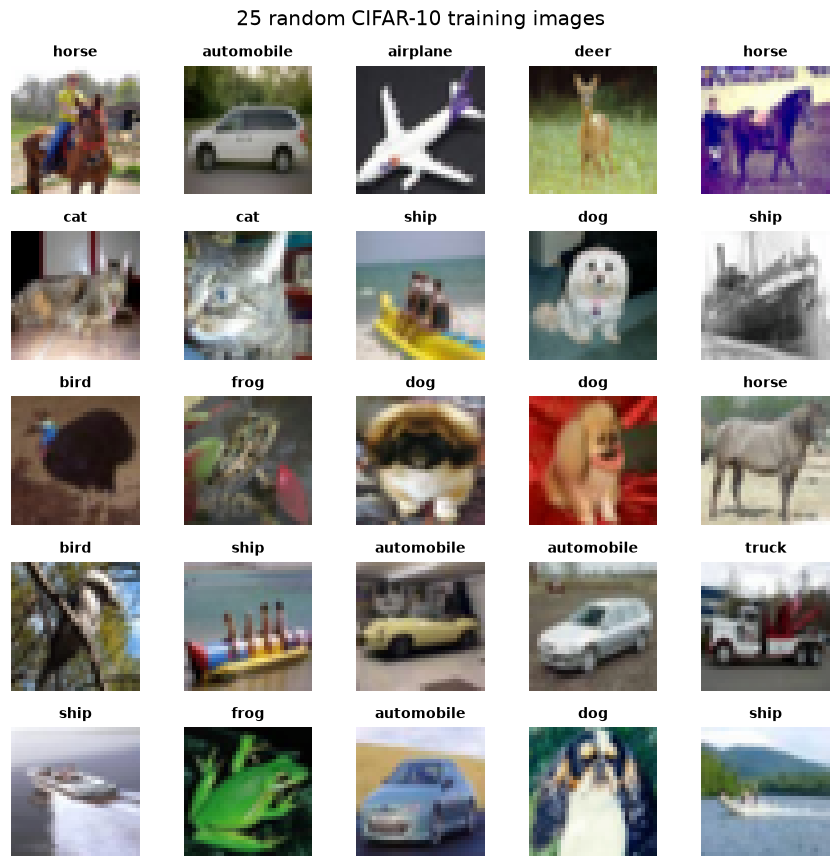

In [3]:
# A quick look at what the network has to learn
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck"]

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for ax in axes.flat:
    idx = random.randrange(len(train_dataset))
    img, label = train_dataset[idx]                      # (3, 32, 32) tensor, normalized
    img = img.permute(1, 2, 0).numpy()                    # -> (32, 32, 3)
    # un-normalize so the image can be displayed
    img = img * np.array([0.2470, 0.2435, 0.2616]) + np.array([0.4914, 0.4822, 0.4465])
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(CIFAR_CLASSES[label], fontsize=9)
    ax.axis("off")
fig.suptitle("25 random CIFAR-10 training images", fontsize=13)
plt.tight_layout()
plt.show()


## 2. Model & shared training loop

**One single architecture for all experiments** (baseline + 4 techniques), so that any difference you see in the charts is caused by the regularization, not by a different network:

```
Conv(3 → 32)   → ReLU → [BN] → MaxPool2×2
Conv(32 → 64)  → ReLU → [BN] → MaxPool2×2
Flatten (64 × 8 × 8 = 4096)
FC(4096 → 512) → ReLU → [Dropout p]
FC(512 → 10)   → logits
```

- `[BN]` and `[Dropout]` blocks exist but are disabled (p = 0); each experiment below enables exactly the one it is about.
- ≈ **2.1 M parameters** for 40k images: plenty of capacity to memorize the training set — an ideal laboratory for regularization.
- `train_net()` trains, evaluates train **and** val after every epoch, and keeps the weights with the best validation accuracy (the "best checkpoint" is what you would actually deploy — it is also what early stopping restores).


In [4]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=10, dropout_rate=0.0, use_batchnorm=False):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32) if use_batchnorm else nn.Identity(),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64) if use_batchnorm else nn.Identity(),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),          # p = 0.0 -> no-op in the baseline
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

n_params = sum(p.numel() for p in ConvNet().parameters())
print(f"Parameters: {n_params:,}")


Parameters: 2,122,186


In [5]:
def evaluate(net, loader, device=DEVICE):
    """Return (mean loss, accuracy %) of `net` on `loader`."""
    net.eval()
    loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x)
            loss += nn.functional.cross_entropy(out, y).item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return loss / total, 100.0 * correct / total


def train_net(net, num_epochs=10, lr=1e-3, weight_decay=0.0,
              early_stop=False, patience=2, l1_lambda=0.0):
    """Train `net` on the train loader, tracking train AND validation every epoch.

    weight_decay > 0 -> L2 regularization; l1_lambda > 0 -> L1 (Lasso) penalty
    (added to the loss, since Adam's weight_decay only implements L2);
    early_stop=True -> stop when the validation accuracy has not improved for
    `patience` consecutive epochs. Returns a `hist` dict of per-epoch metrics.
    """
    net.to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_state, bad_epochs = -1.0, None, 0

    for epoch in range(1, num_epochs + 1):
        net.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(net(x), y)
            if l1_lambda > 0.0:                  # L1 (Lasso): Adam weight_decay is L2-only
                loss = loss + l1_lambda * sum(p.abs().sum() for p in net.parameters())
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(net, train_loader)
        val_loss, val_acc = evaluate(net, val_loader)
        hist["train_loss"].append(train_loss); hist["train_acc"].append(train_acc)
        hist["val_loss"].append(val_loss);     hist["val_acc"].append(val_acc)

        print(f"Epoch {epoch:2d}/{num_epochs} | "
              f"train loss {train_loss:.4f} (acc {train_acc:.2f}%) | "
              f"val loss {val_loss:.4f} (acc {val_acc:.2f}%)")

        # remember the best checkpoint found so far
        if val_acc > best_val_acc:
            best_val_acc, bad_epochs = val_acc, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad_epochs += 1

        if early_stop and bad_epochs >= patience:
            print(f"Early stopping after epoch {epoch}: "
                  f"no validation improvement for {patience} consecutive epochs "
                  f"(best val acc {best_val_acc:.2f}%)")
            break

    # restore the best checkpoint (this is the model we would deploy)
    net.load_state_dict(best_state)
    hist["stopped_at"] = len(hist["val_acc"])
    return hist


In [6]:
BLUE, RED = "tab:blue", "tab:red"
BASE_BLUE, BASE_RED = "#a9c7e8", "#f2a5a5"   # faint reference colours for the baseline overlay


def visualize_training_history(hist, title, base=None):
    """Annotated train/val curves with the overfitting story marked explicitly.

    If `base` (a baseline hist dict) is given, its train/val curves are drawn
    first as faint dashed reference lines, so the technique can be compared
    against the unregularized model at a glance.
    """
    tl, ta = hist["train_loss"], hist["train_acc"]
    vl, va = hist["val_loss"], hist["val_acc"]
    ep = np.arange(1, len(tl) + 1)

    if base is not None:
        btl, bta = base["train_loss"], base["train_acc"]
        bvl, bva = base["val_loss"], base["val_acc"]
        bep = np.arange(1, len(btl) + 1)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13.5, 4.6))

    # faint baseline reference curves, drawn first so the technique sits on top
    if base is not None:
        ax_loss.plot(bep, btl, color=BASE_BLUE, ls="--", lw=1.2, zorder=1, label="Baseline (train)")
        ax_loss.plot(bep, bvl, color=BASE_RED,  ls="--", lw=1.2, zorder=1, label="Baseline (validation)")
        ax_acc.plot(bep, bta, color=BASE_BLUE, ls="--", lw=1.2, zorder=1, label="Baseline (train)")
        ax_acc.plot(bep, bva, color=BASE_RED,  ls="--", lw=1.2, zorder=1, label="Baseline (validation)")

    # ---------------- left: loss ----------------
    ax_loss.plot(ep, tl, color=BLUE, marker="o", ms=3, lw=1.6, label="Train loss")
    ax_loss.plot(ep, vl, color=RED,  marker="o", ms=3, lw=1.6, label="Validation loss")
    ax_loss.set_title(f"{title} \u2014 loss")
    ax_loss.set_xlabel("Epoch"); ax_loss.set_ylabel("Cross-entropy loss")
    ax_loss.legend(loc="lower left", fontsize=8.5)

    # overfitting "starts" where the val loss first turns up after its best (lowest)
    # value; if it never climbs meaningfully the model does not (yet) overfit
    best_i = int(np.argmin(vl))
    if max(vl[best_i:]) > vl[best_i] * 1.15:
        i = best_i + 1
        while i < len(vl) and vl[i] <= vl[best_i]:
            i += 1
        ax_loss.annotate(
            "overfitting starts here:\nval loss climbs while train\nloss keeps falling",
            xy=(ep[i], vl[i]), xytext=(0.02, 0.88), textcoords="axes fraction", va="top",
            arrowprops=dict(arrowstyle="->", color="black", alpha=0.7),
            fontsize=9, zorder=10, bbox=dict(boxstyle="round,pad=0.3", fc="#fff3cd", ec="orange"))
    else:
        ax_loss.annotate("no clear divergence:\nmodel does not (yet) overfit",
                         xy=(0.02, 0.88), textcoords="axes fraction",
                         va="top", zorder=10, annotation_clip=False,
                         fontsize=9, bbox=dict(boxstyle="round,pad=0.3",
                                               fc="#d4edda", ec="green"))

    # ---------------- right: accuracy ----------------
    ax_acc.plot(ep, ta, color=BLUE, marker="o", ms=3, lw=1.6, label="Train accuracy")
    ax_acc.plot(ep, va, color=RED,  marker="o", ms=3, lw=1.6, label="Validation accuracy")
    ax_acc.set_title(f"{title} \u2014 accuracy")
    ax_acc.set_xlabel("Epoch"); ax_acc.set_ylabel("Accuracy (%)")
    all_acc = list(ta) + list(va) + (list(bta) + list(bva) if base is not None else [])
    ax_acc.set_ylim(max(0, min(all_acc) - 4), 101)
    best_a = int(np.argmax(va))
    ax_acc.plot(ep[best_a], va[best_a], marker="*", ms=16, color="gold",
                mec="black", zorder=5)
    ax_acc.annotate(f"best val accuracy:\n{va[best_a]:.1f}% (epoch {ep[best_a]})",
                    xy=(ep[best_a], va[best_a]),
                    xytext=(0.97, 0.04), textcoords="axes fraction", ha="right", va="bottom",
                    fontsize=9, zorder=10, bbox=dict(boxstyle="round,pad=0.3", fc="#d4edda", ec="green"))

    # final train/validation gap — the number that tells the overfitting story
    gap = ta[-1] - va[-1]
    ax_acc.text(0.15, 0.03,
                f"final train acc: {ta[-1]:.1f}%\nfinal val acc:   {va[-1]:.1f}%\n"
                f"train\u2013val gap: {gap:.1f} pts",
                transform=ax_acc.transAxes, fontsize=9, va="bottom", zorder=10,
                bbox=dict(boxstyle="round,pad=0.35", fc="#e7f1ff", ec=BLUE))

    ax_acc.legend(loc="upper left", fontsize=8.5)
    plt.tight_layout()
    plt.show()


## 3. Baseline — no regularization

**What we do:** train the plain CNN (no weight decay, no dropout, no batch norm) for all 10 epochs.

**What to expect:** training loss/accuracy improves steadily, while validation performance peaks early and then degrades — the classic overfitting signature. This is the bar the other four techniques have to beat on **validation accuracy**.


In [7]:
model = ConvNet()
baseline = train_net(model, num_epochs=10)


Epoch  1/10 | train loss 0.9672 (acc 66.56%) | val loss 1.0420 (acc 63.31%)
Epoch  2/10 | train loss 0.7255 (acc 75.03%) | val loss 0.9045 (acc 68.34%)
Epoch  3/10 | train loss 0.5346 (acc 82.20%) | val loss 0.8737 (acc 69.77%)
Epoch  4/10 | train loss 0.3699 (acc 88.01%) | val loss 0.8891 (acc 70.56%)
Epoch  5/10 | train loss 0.2287 (acc 93.18%) | val loss 0.9476 (acc 70.85%)
Epoch  6/10 | train loss 0.1222 (acc 96.33%) | val loss 1.0964 (acc 71.71%)
Epoch  7/10 | train loss 0.0710 (acc 97.88%) | val loss 1.3077 (acc 71.26%)
Epoch  8/10 | train loss 0.0756 (acc 97.59%) | val loss 1.4545 (acc 70.53%)
Epoch  9/10 | train loss 0.0803 (acc 97.23%) | val loss 1.6146 (acc 69.31%)
Epoch 10/10 | train loss 0.0506 (acc 98.42%) | val loss 1.6937 (acc 70.47%)


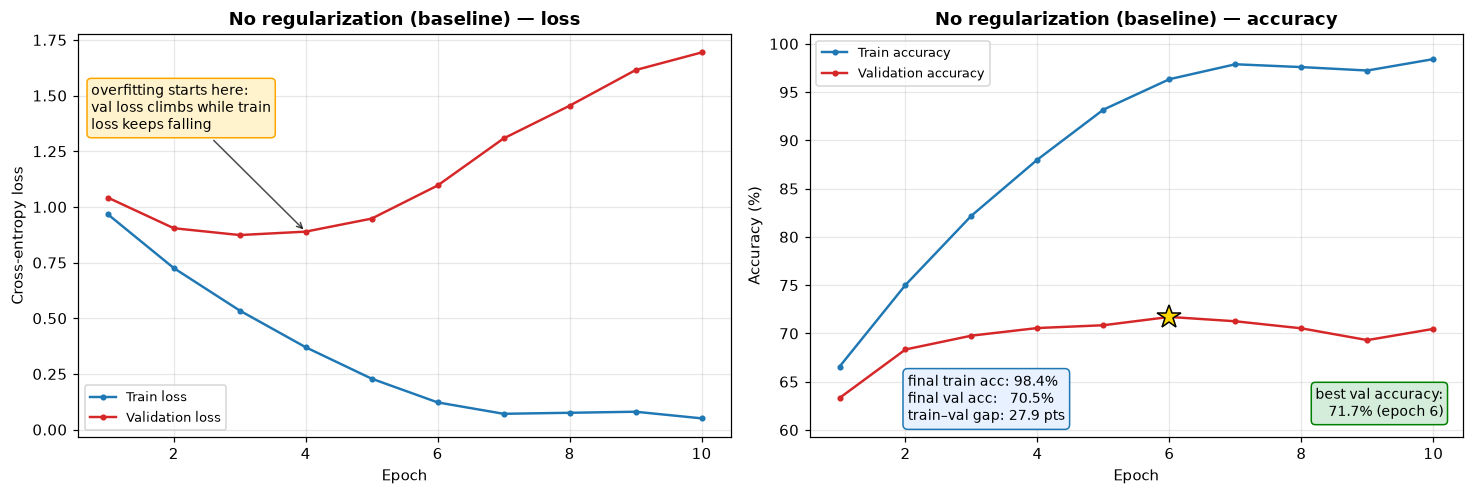

In [8]:
visualize_training_history(baseline, "No regularization (baseline)")


## 4. L1 regularization (Lasso)

**What we do:** add an L1 (Lasso) penalty `λ · Σ|w|` (λ = 1e-5) to the loss. Unlike L2 — which *shrinks* every weight smoothly — L1 pushes many weights **exactly to zero**, yielding a *sparse* model (a built-in form of feature selection).

> **Why not just use `weight_decay`?** PyTorch's optimizer `weight_decay` only implements the L2 penalty, so the L1 term is added to the loss by hand inside the shared `train_net()` loop.

**What to watch:** on a vision CNN, L1 rarely beats L2 on raw validation accuracy — its payoff is **sparsity**, which we visualize explicitly in the last cell of this section.


In [9]:
baseline_model = model          # keep the baseline weights -> for the sparsity comparison below
model = ConvNet()
l1 = train_net(model, num_epochs=10, l1_lambda=1e-5)


Epoch  1/10 | train loss 0.9547 (acc 66.76%) | val loss 1.0255 (acc 63.73%)
Epoch  2/10 | train loss 0.7568 (acc 73.35%) | val loss 0.9178 (acc 67.81%)
Epoch  3/10 | train loss 0.6087 (acc 79.41%) | val loss 0.8589 (acc 69.94%)
Epoch  4/10 | train loss 0.5080 (acc 82.62%) | val loss 0.8640 (acc 69.88%)
Epoch  5/10 | train loss 0.3369 (acc 89.51%) | val loss 0.8281 (acc 71.67%)
Epoch  6/10 | train loss 0.2605 (acc 91.36%) | val loss 0.9415 (acc 71.70%)
Epoch  7/10 | train loss 0.1790 (acc 94.58%) | val loss 0.9900 (acc 71.55%)
Epoch  8/10 | train loss 0.1309 (acc 96.36%) | val loss 1.0474 (acc 71.09%)
Epoch  9/10 | train loss 0.1154 (acc 96.31%) | val loss 1.2159 (acc 70.96%)
Epoch 10/10 | train loss 0.1046 (acc 96.75%) | val loss 1.3126 (acc 70.65%)


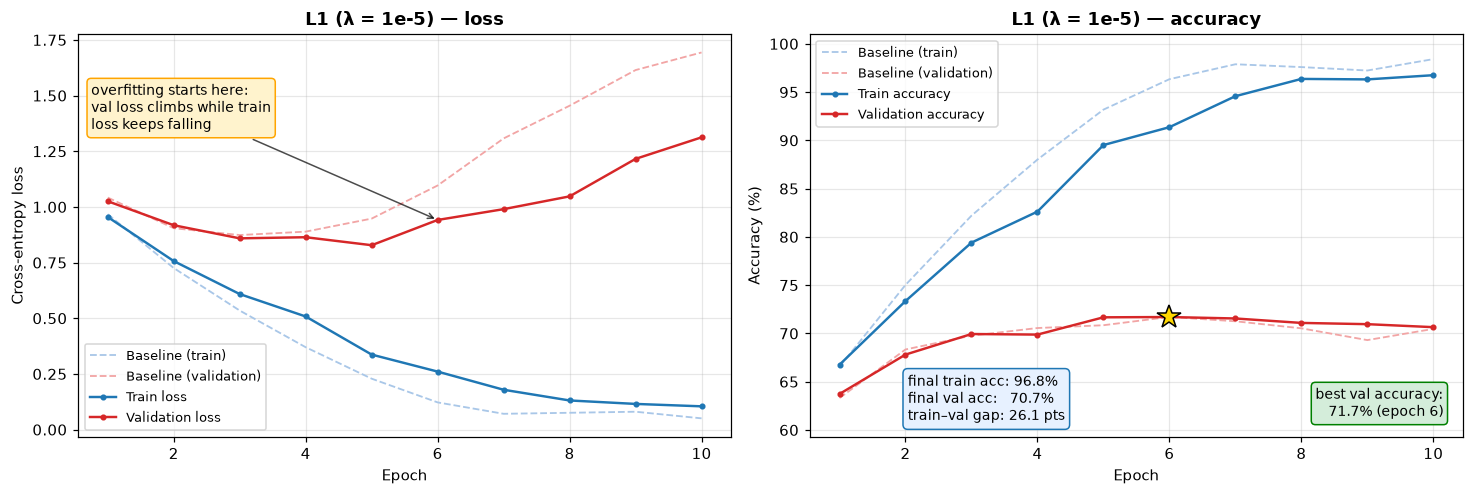

In [10]:
visualize_training_history(l1, "L1 (λ = 1e-5)", base=baseline)


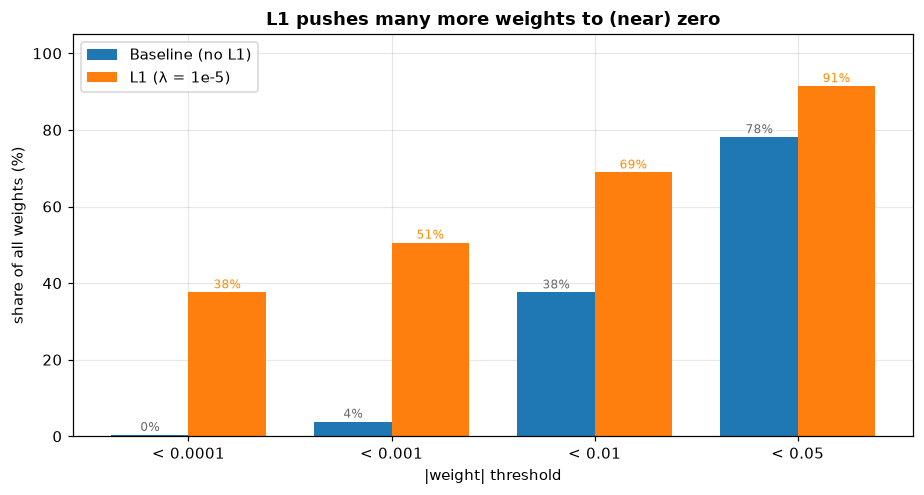

In [11]:
# L1's signature: it drives many more weights to (near) zero than the baseline.
def frac_below(net, t):
    w = np.concatenate([p.detach().abs().cpu().numpy().ravel() for p in net.parameters()])
    return float((w < t).mean() * 100.0)

threshs = [1e-4, 1e-3, 1e-2, 5e-2]
base_f  = [frac_below(baseline_model, t) for t in threshs]
l1_f    = [frac_below(model, t) for t in threshs]

x = np.arange(len(threshs))
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.bar(x - 0.19, base_f, 0.38, color=BLUE,         label="Baseline (no L1)")
ax.bar(x + 0.19, l1_f,   0.38, color="tab:orange", label="L1 (λ = 1e-5)")
for xi, b, l in zip(x, base_f, l1_f):
    ax.text(xi - 0.19, b + 1, f"{b:.0f}%", ha="center", fontsize=8, color="dimgray")
    ax.text(xi + 0.19, l + 1, f"{l:.0f}%", ha="center", fontsize=8, color="darkorange")
ax.set_xticks(x, [f"< {t:g}" for t in threshs])
ax.set_xlabel("|weight| threshold")
ax.set_ylabel("share of all weights (%)")
ax.set_title("L1 pushes many more weights to (near) zero")
ax.set_ylim(0, 105)
ax.legend()
plt.tight_layout()
plt.show()


## 5. L2 regularisation (weight decay)

**What we do:** add `weight_decay=1e-3` to the optimizer. Every step now also nudges the weights toward zero — the model is pushed toward a simpler (lower-magnitude) solution.

**What to watch:** the train/val gap should be *smaller* than in the baseline, even though training loss now drops more slowly.


In [12]:
model = ConvNet()
l2 = train_net(model, num_epochs=10, weight_decay=1e-3)


Epoch  1/10 | train loss 1.0240 (acc 63.69%) | val loss 1.0801 (acc 61.43%)
Epoch  2/10 | train loss 0.8291 (acc 71.45%) | val loss 0.9299 (acc 67.55%)
Epoch  3/10 | train loss 0.7404 (acc 73.71%) | val loss 0.9029 (acc 67.67%)
Epoch  4/10 | train loss 0.6420 (acc 78.57%) | val loss 0.8575 (acc 70.20%)
Epoch  5/10 | train loss 0.5726 (acc 81.07%) | val loss 0.8345 (acc 71.01%)
Epoch  6/10 | train loss 0.4684 (acc 84.81%) | val loss 0.7997 (acc 72.15%)
Epoch  7/10 | train loss 0.4153 (acc 86.33%) | val loss 0.8336 (acc 71.85%)
Epoch  8/10 | train loss 0.3458 (acc 88.72%) | val loss 0.8380 (acc 71.92%)
Epoch  9/10 | train loss 0.2953 (acc 90.85%) | val loss 0.8270 (acc 72.38%)
Epoch 10/10 | train loss 0.2467 (acc 92.18%) | val loss 0.8852 (acc 72.15%)


<cell 8>:50: UserWarning: You have used the `textcoords` kwarg, but not the `xytext` kwarg.  This can lead to surprising results.


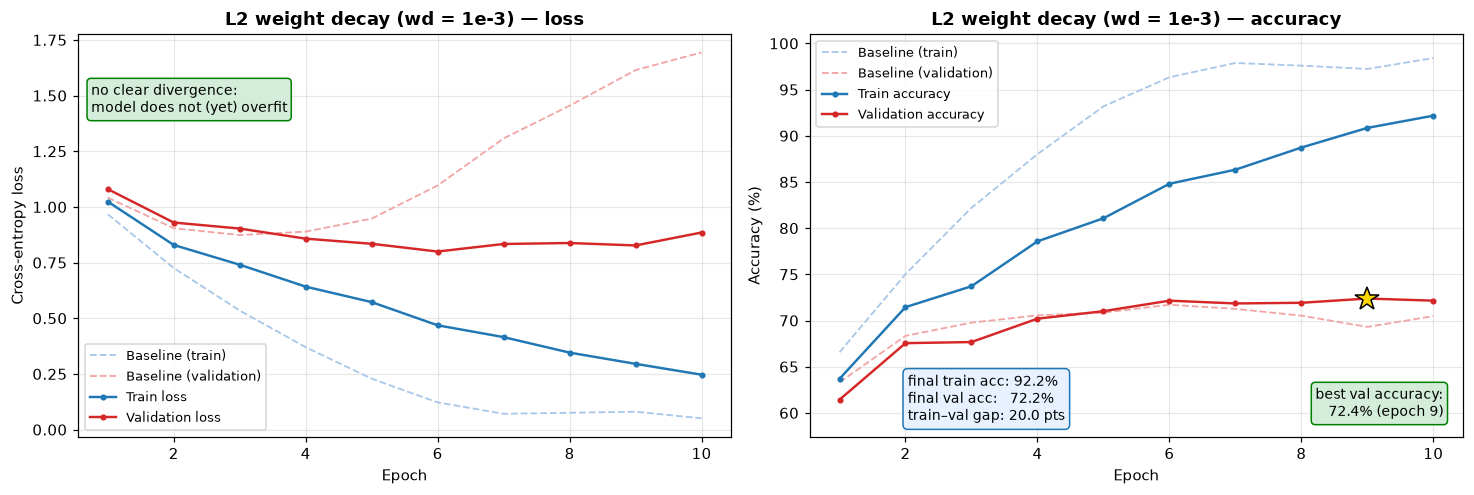

In [13]:
visualize_training_history(l2, "L2 weight decay (wd = 1e-3)", base=baseline)


## 6. Early stopping

**What we do:** train without any penalty, but stop as soon as the validation accuracy fails to improve for `patience = 2` consecutive epochs, then restore the best checkpoint (see `train_net`).

**What to watch:** training is *cut short*. This technique answers the question "after how many epochs does more training start to hurt?" Compare the epoch of the val peak with the number of epochs actually used.


In [14]:
model = ConvNet()
early = train_net(model, num_epochs=10, early_stop=True, patience=2)
print(f"\nTraining stopped at epoch {early['stopped_at']} of 10.")


Epoch  1/10 | train loss 0.9669 (acc 65.53%) | val loss 1.0313 (acc 63.07%)
Epoch  2/10 | train loss 0.7246 (acc 75.08%) | val loss 0.8974 (acc 68.79%)
Epoch  3/10 | train loss 0.5380 (acc 81.92%) | val loss 0.8430 (acc 70.79%)
Epoch  4/10 | train loss 0.3676 (acc 88.32%) | val loss 0.8392 (acc 71.55%)
Epoch  5/10 | train loss 0.2429 (acc 92.96%) | val loss 0.8876 (acc 71.46%)
Epoch  6/10 | train loss 0.1203 (acc 96.76%) | val loss 1.0355 (acc 71.68%)
Epoch  7/10 | train loss 0.1266 (acc 95.72%) | val loss 1.2595 (acc 70.34%)
Epoch  8/10 | train loss 0.0673 (acc 97.89%) | val loss 1.3998 (acc 71.02%)
Early stopping after epoch 8: no validation improvement for 2 consecutive epochs (best val acc 71.68%)

Training stopped at epoch 8 of 10.


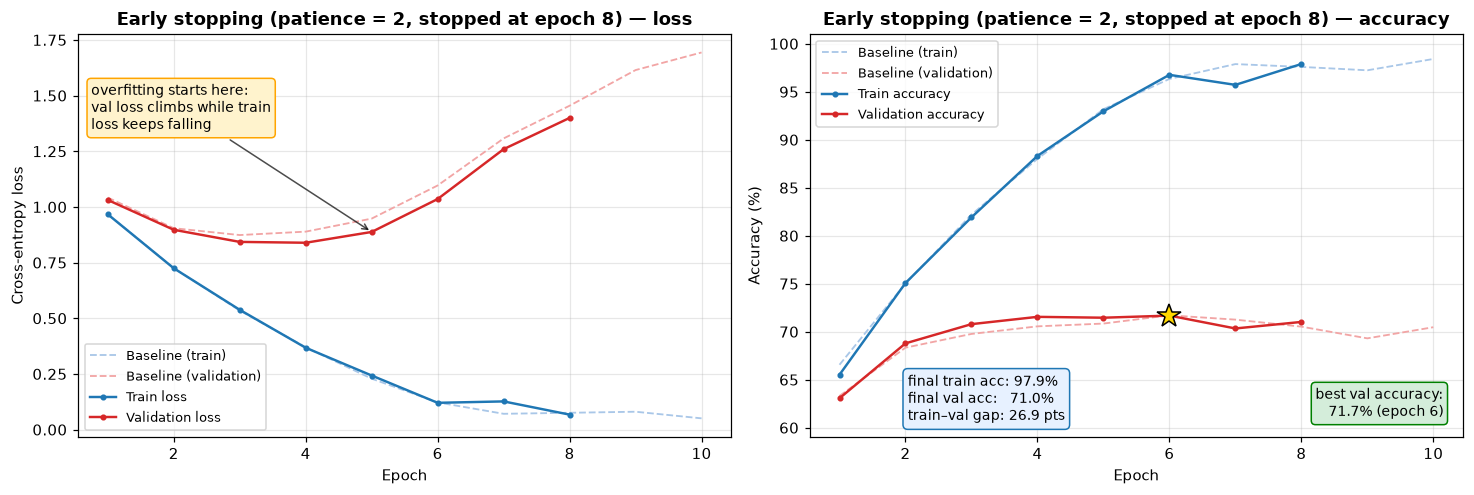

In [15]:
visualize_training_history(early, f"Early stopping (patience = 2, stopped at epoch {early['stopped_at']})", base=baseline)


## 7. Dropout

**What we do:** randomly drop p = 0.2 of the hidden units on every training step. Dropout is active only in *training mode* — at inference the layer is a no-op, so it costs nothing in production.

**What to watch:** slower progress on the training set (intentional — the network can no longer rely on any single neuron) and a flatter, better-generalizing validation curve.


In [16]:
model = ConvNet(dropout_rate=0.2)
drop = train_net(model, num_epochs=10)


Epoch  1/10 | train loss 0.9401 (acc 66.69%) | val loss 1.0083 (acc 64.18%)
Epoch  2/10 | train loss 0.7144 (acc 75.56%) | val loss 0.8705 (acc 69.14%)
Epoch  3/10 | train loss 0.5479 (acc 81.31%) | val loss 0.8329 (acc 71.70%)
Epoch  4/10 | train loss 0.3701 (acc 88.45%) | val loss 0.7849 (acc 73.30%)
Epoch  5/10 | train loss 0.2671 (acc 91.91%) | val loss 0.8309 (acc 72.65%)
Epoch  6/10 | train loss 0.1645 (acc 95.20%) | val loss 0.8842 (acc 73.34%)
Epoch  7/10 | train loss 0.1382 (acc 95.61%) | val loss 1.0318 (acc 71.96%)
Epoch  8/10 | train loss 0.0833 (acc 97.57%) | val loss 1.0975 (acc 72.63%)
Epoch  9/10 | train loss 0.0513 (acc 98.72%) | val loss 1.1344 (acc 73.15%)
Epoch 10/10 | train loss 0.0457 (acc 98.83%) | val loss 1.2158 (acc 73.16%)


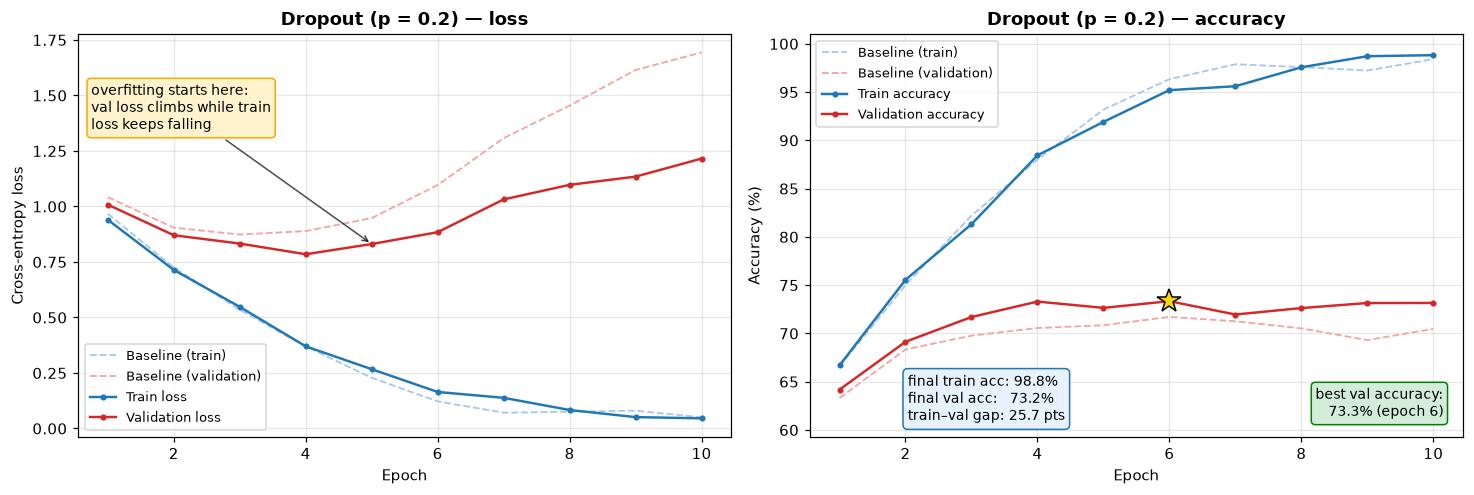

In [17]:
visualize_training_history(drop, "Dropout (p = 0.2)", base=baseline)


## 8. Batch normalization

**What we do:** insert a BatchNorm layer after each convolution, normalizing each layer's inputs over the current mini-batch. This is mainly a *training-stability* technique (higher learning rates work, smoother loss landscape), but it also acts as a mild regularizer because of the per-batch noise.

**What to watch:** typically the fastest, most stable convergence of all four techniques here.


In [18]:
model = ConvNet(use_batchnorm=True)
bnorm = train_net(model, num_epochs=10)


Epoch  1/10 | train loss 1.0613 (acc 62.74%) | val loss 1.1192 (acc 60.33%)
Epoch  2/10 | train loss 0.8236 (acc 70.82%) | val loss 0.9237 (acc 67.16%)
Epoch  3/10 | train loss 0.7246 (acc 74.26%) | val loss 0.9061 (acc 68.37%)
Epoch  4/10 | train loss 0.5842 (acc 79.41%) | val loss 0.8107 (acc 71.47%)
Epoch  5/10 | train loss 0.4978 (acc 82.92%) | val loss 0.7892 (acc 72.80%)
Epoch  6/10 | train loss 0.4694 (acc 83.43%) | val loss 0.8302 (acc 72.13%)
Epoch  7/10 | train loss 0.4007 (acc 85.98%) | val loss 0.8514 (acc 72.77%)
Epoch  8/10 | train loss 0.3672 (acc 87.01%) | val loss 0.8801 (acc 72.04%)
Epoch  9/10 | train loss 0.2762 (acc 90.82%) | val loss 0.8720 (acc 72.91%)
Epoch 10/10 | train loss 0.2342 (acc 92.03%) | val loss 0.9169 (acc 72.90%)


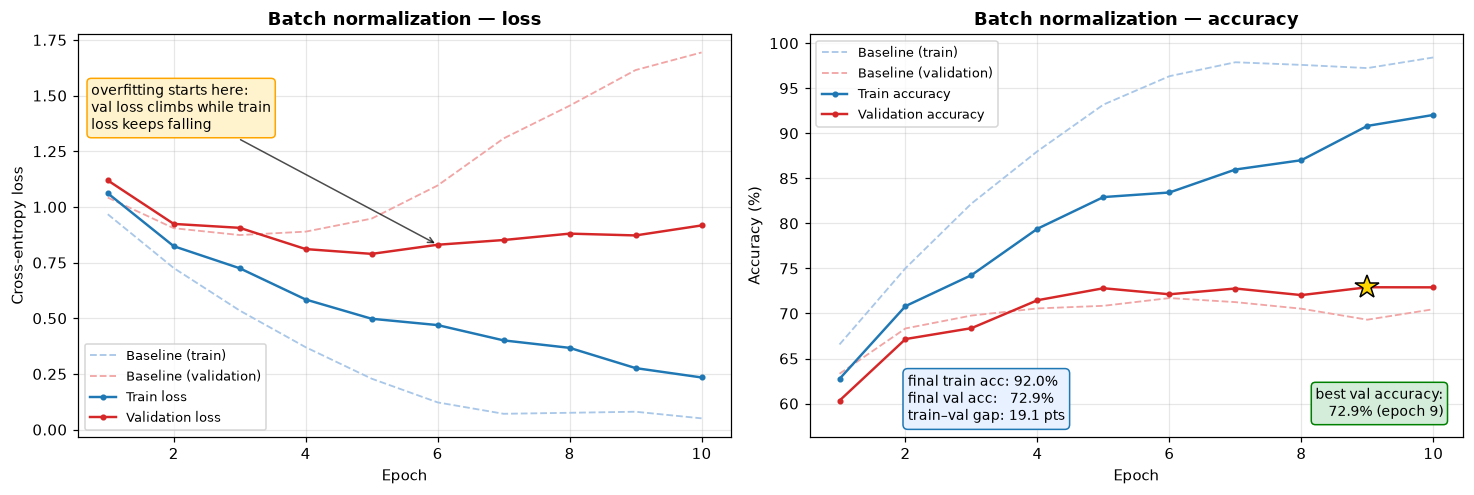

In [19]:
visualize_training_history(bnorm, "Batch normalization", base=baseline)


## 9. Summary — all techniques at a glance

The two charts below answer: "which technique generalizes best on CIFAR-10, and how large is its effect?"


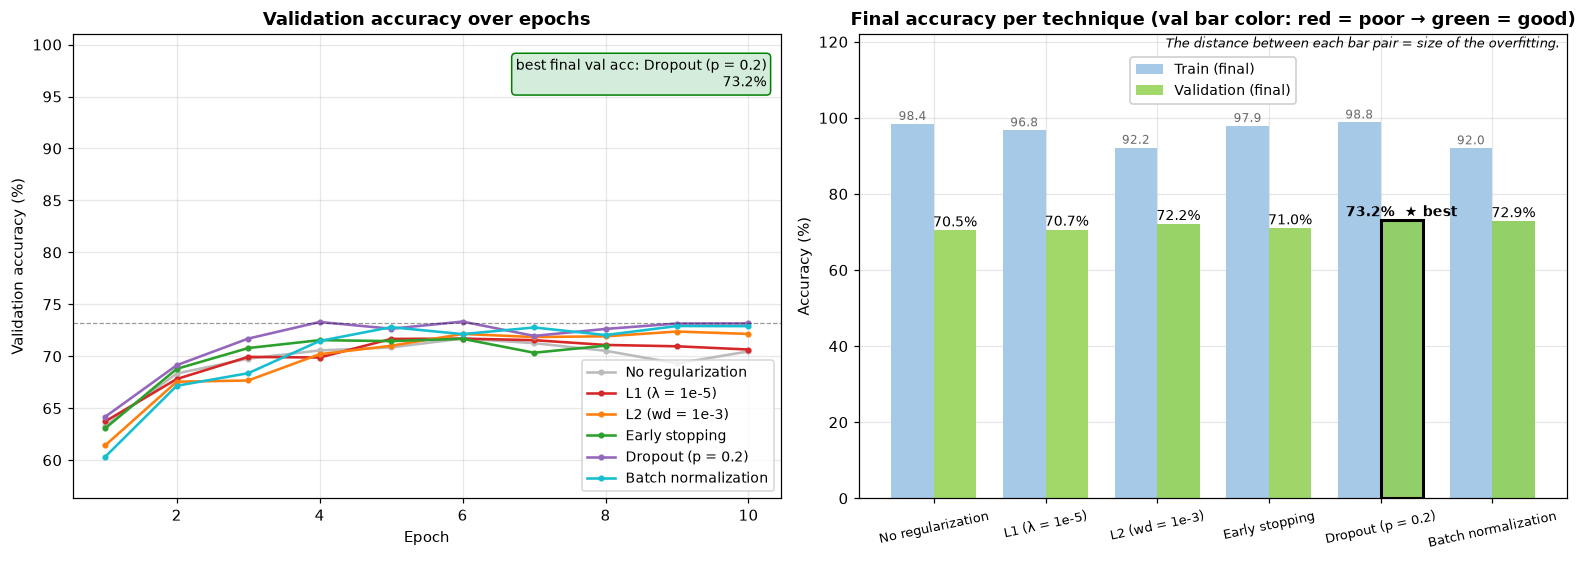

In [20]:
results = [
    ("No regularization",   baseline),
    ("L1 (λ = 1e-5)",       l1),
    ("L2 (wd = 1e-3)",      l2),
    ("Early stopping",      early),
    ("Dropout (p = 0.2)",   drop),
    ("Batch normalization", bnorm),
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2))

# --- (1) validation accuracy over epochs for every technique -----------------
colors = ["#bbbbbb", "tab:red", "tab:orange", "tab:green", "tab:purple", "tab:cyan"]
for (name, hist), color in zip(results, colors):
    ep = np.arange(1, len(hist["val_acc"]) + 1)
    ax1.plot(ep, hist["val_acc"], marker="o", ms=3, lw=1.7, color=color, label=name)
best_final = max(h["val_acc"][-1] for _, h in results)
best_name = [n for n, h in results if h["val_acc"][-1] == best_final][0]
ax1.axhline(best_final, ls="--", lw=0.8, color="black", alpha=0.4)
ax1.annotate(f"best final val acc: {best_name}\n{best_final:.1f}%",
             xy=(0.98, 0.95), xycoords="axes fraction", ha="right", va="top",
             fontsize=9, zorder=10, bbox=dict(boxstyle="round,pad=0.3", fc="#d4edda", ec="green"))
ax1.set_title("Validation accuracy over epochs")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Validation accuracy (%)")
ax1.set_ylim(max(0, min(min(h["val_acc"]) for _, h in results) - 4), 101)
ax1.legend(loc="lower right", fontsize=9)

# --- (2) final train vs validation accuracy per technique (gap = the story) --
x = np.arange(len(results))
trains = [h["train_acc"][-1] for _, h in results]
vals_  = [h["val_acc"][-1] for _, h in results]
best_i = int(np.argmax(vals_))
norm = Normalize(min(min(vals_), 0), 100)

ax2.bar(x - 0.19, trains, 0.38, color="#a6c9e8", label="Train (final)")
val_bars = ax2.bar(x + 0.19, vals_, 0.38,
                   color=[plt.get_cmap("RdYlGn")(norm(v)) for v in vals_],
                   label="Validation (final)")
for i, v in enumerate(vals_):                     # green = good, red = bad
    val_bars[i].set_edgecolor("black" if i == best_i else "white")
    val_bars[i].set_linewidth(2.0 if i == best_i else 0.0)
for xi, t in zip(x, trains):
    ax2.text(xi - 0.19, t + 1, f"{t:.1f}", ha="center", fontsize=8, color="dimgray")
for xi, v in zip(x, vals_):
    lbl = f"{v:.1f}%"
    if xi == best_i:
        lbl += "  \u2605 best"
    ax2.text(xi + 0.19, v + 1, lbl, ha="center", fontsize=9,
             fontweight="bold" if xi == best_i else "normal")
ax2.set_title("Final accuracy per technique (val bar color: red = poor \u2192 green = good)")
ax2.set_xticks(x, [n for n, _ in results], fontsize=8.5, rotation=12)
ax2.set_ylabel("Accuracy (%)"); ax2.set_ylim(0, 122)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, 0.965), fontsize=9, framealpha=1.0)
ax2.text(0.99, 0.995,
         "The distance between each bar pair = size of the overfitting.",
         transform=ax2.transAxes, fontsize=8.2, va="top", ha="right", style="italic")

plt.tight_layout()
plt.show()


### What to take away

- **Overfitting is visible, not invisible**: with enough capacity, *every* technique changes the validation curve on a harder dataset — on MNIST they looked almost identical because the baseline barely overfit there.
- **Judge techniques only by validation/test performance.** A technique that *lowers* training accuracy (L2, dropout) can still be the best one if it raises validation accuracy.
- **Regularization = trade-off between fit and simplicity** — the summary chart shows exactly where that trade-off lands for each technique on CIFAR-10.
- The remaining question: *what are the best hyperparameters at all* (learning rate, dropout rate, batch size)? The next section answers that with **Optuna**.


# Hyperparameter Optimization with Optuna

Now we let a search algorithm find the best settings instead of guessing. **Optuna** tries many combinations (called *trials*), learns from past results, and spends more trials in promising regions.

**Search space** (same convolutional network as above, `3` epochs per trial for speed):

| Hyperparameter | Range | Type |
|----------------|-------|------|
| `lr` (learning rate) | 1e-5 … 1e-1 | continuous, log-scaled |
| `dropout_rate` | 0.0 … 0.5 | continuous |
| `batch_size` | 32, 64, 128, 256 | categorical |

20 trials are fast to run; the charts below become more meaningful with 50–100 trials (linear time cost).


In [21]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

NUM_TRIALS = 20          # more trials -> more reliable optimum, linear time cost
EPOCHS_PER_TRIAL = 3     # trials are cheap on purpose; retrain the winner for 10+ epochs


def objective(trial):
    """One trial: build a ConvNet with the trial's hyperparameters,
    train it for EPOCHS_PER_TRIAL epochs, and report validation accuracy."""
    lr       = trial.suggest_float("lr", 1e-5, 1e-1, log=True)
    dropout_ = trial.suggest_float("dropout_rate", 0.0, 0.5)
    batch    = trial.suggest_categorical("batch_size", [32, 64, 128, 256])

    net = ConvNet(dropout_rate=dropout_).to(DEVICE)
    loader = DataLoader(train_dataset, batch_size=batch, shuffle=True)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for _ in range(EPOCHS_PER_TRIAL):
        net.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(net(xb), yb).backward()
            optimizer.step()

    _, val_acc = evaluate(net, val_loader)
    return val_acc


In [22]:
study = optuna.create_study(direction="maximize")     # we maximize validation accuracy
study.optimize(objective, n_trials=NUM_TRIALS)

print(f"Number of finished trials: {len(study.trials)}")
print(f"Best trial: #{study.best_trial.number}")
print(f"  validation accuracy: {study.best_trial.value:.2f}%")
print("  params:")
for k, v in study.best_trial.params.items():
    print(f"    {k} = {v}" + (f" ({v:.1e})" if k == "lr" else ""))


Number of finished trials: 20
Best trial: #19
  validation accuracy: 70.82%
  params:
    lr = 0.0007160157148232943 (7.2e-04)
    dropout_rate = 0.15026991383549837
    batch_size = 32


## Reading the four charts

One color code is used **consistently in all of them**:

**green = good** (high validation accuracy), **red = bad** (low validation accuracy). Every dot or bar is colored by that trial's result, so "*which values are good and which are bad?*" is read straight from the color. The ⭐ star marks the best trial of the whole study.
In the **parallel coordinates** chart, each line is one trial: its height on each vertical axis is that trial's setting, so a line's *shape* is its full hyperparameter combination — you can see at a glance which combinations score well.


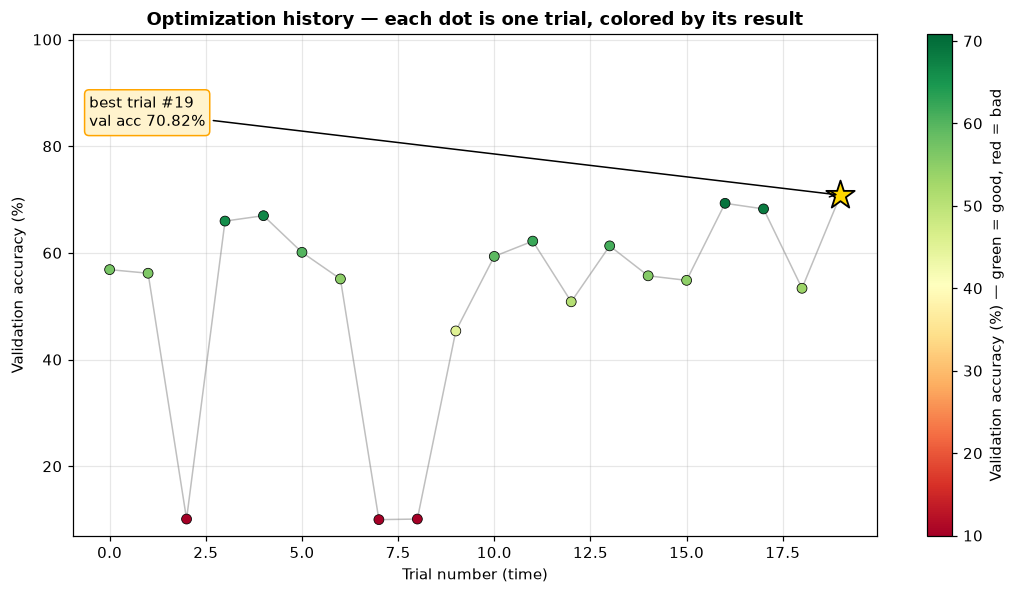

In [23]:
trials = [t for t in study.trials if t.value is not None]   # ignore failed trials
values = np.array([t.value for t in trials])
nums = np.array([t.number for t in trials])
cmap = plt.get_cmap("RdYlGn")
norm = Normalize(float(values.min()), float(values.max()))

# ---------------- (1) optimization history ----------------
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(nums, values, color="gray", lw=1, alpha=0.5)
ax.scatter(nums, values, c=values, cmap=cmap, vmin=norm.vmin, vmax=norm.vmax,
           s=42, edgecolor="black", linewidth=0.5, zorder=3)
bi = int(values.argmax())
ax.scatter(nums[bi], values[bi], s=380, marker="*", facecolor="gold",
           edgecolor="black", linewidth=1.2, zorder=5)
ax.annotate(f"best trial #{nums[bi]}\nval acc {values[bi]:.2f}%",
            xy=(nums[bi], values[bi]),
            xytext=(0.02, 0.88), textcoords="axes fraction", va="top",
            arrowprops=dict(arrowstyle="->", color="black"),
            fontsize=10, zorder=10, bbox=dict(boxstyle="round,pad=0.3", fc="#fff3cd", ec="orange"))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
cb = plt.colorbar(sm, ax=ax)
cb.set_label("Validation accuracy (%) — green = good, red = bad")
ax.set_title("Optimization history — each dot is one trial, colored by its result")
ax.set_xlabel("Trial number (time)"); ax.set_ylabel("Validation accuracy (%)")
ax.set_ylim(min(values) - 3, 101)
plt.tight_layout()
plt.show()


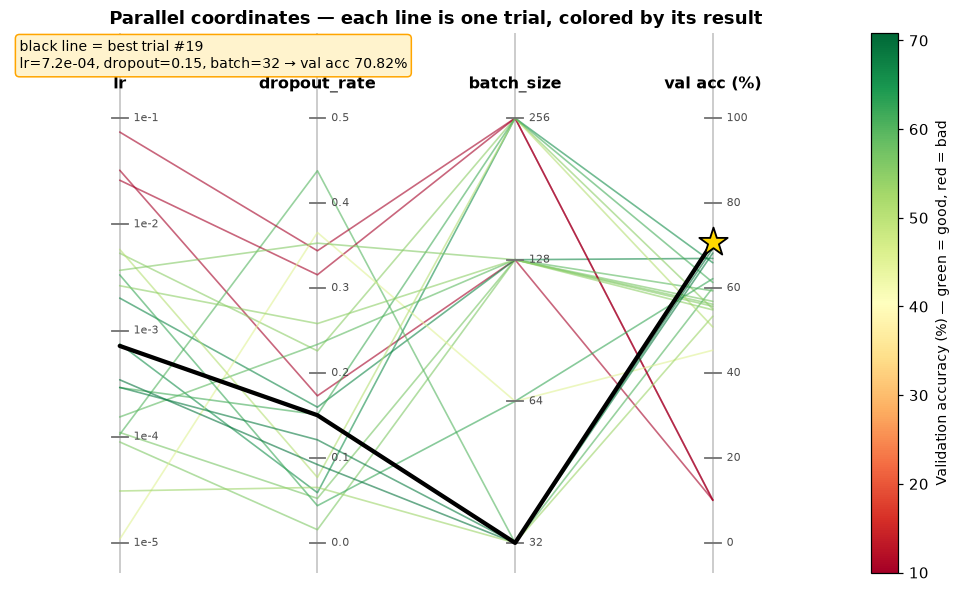

In [24]:
# ---------------- (2) parallel coordinates: each line = one trial ----------
# like TensorBoard's "hyperparameter parallel coordinates" view: one vertical
# axis per hyperparameter, one polyline per trial; the line's height on each
# axis is that trial's setting, so a line's *shape* is its full combination.
ax_names = ["lr", "dropout_rate", "batch_size", "val acc (%)"]

def ppos(name, v):
    """Position of value v on its axis, normalized to 0..1 (bottom..top)."""
    if name == "lr":           return (np.log10(v) + 5) / 4        # 1e-5..1e-1, log
    if name == "dropout_rate": return v / 0.5
    if name == "batch_size":   return {32: 0.0, 64: 1/3, 128: 2/3, 256: 1.0}[v]
    return v / 100.0                                               # val acc

pticks = {
    "lr":           ([1e-5, 1e-4, 1e-3, 1e-2, 1e-1], ["1e-5", "1e-4", "1e-3", "1e-2", "1e-1"]),
    "dropout_rate": ([0.0, 0.1, 0.2, 0.3, 0.4, 0.5], ["0.0", "0.1", "0.2", "0.3", "0.4", "0.5"]),
    "batch_size":   ([32, 64, 128, 256], ["32", "64", "128", "256"]),
    "val acc (%)":  ([0, 20, 40, 60, 80, 100], ["0", "20", "40", "60", "80", "100"]),
}

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bi = int(values.argmax())
for k, t in enumerate(trials):
    is_best = (k == bi)
    ys = [ppos("lr", t.params["lr"]), ppos("dropout_rate", t.params["dropout_rate"]),
          ppos("batch_size", t.params["batch_size"]), ppos("val acc (%)", t.value)]
    ax.plot(np.arange(4), ys,
            color="black" if is_best else cmap(norm(t.value)),
            lw=2.8 if is_best else 1.1, alpha=1.0 if is_best else 0.6,
            zorder=4 if is_best else 2, solid_capstyle="round")
ax.scatter([3], [ppos("val acc (%)", values[bi])], s=380, marker="*",
           facecolor="gold", edgecolor="black", linewidth=1.2, zorder=6)
for k, name in enumerate(ax_names):
    ax.axvline(k, color="0.75", lw=1, zorder=1)
    for v, lab in zip(*pticks[name]):
        y = ppos(name, v)
        ax.plot([k - 0.04, k + 0.04], [y, y], color="0.45", lw=1.2, zorder=3)
        ax.text(k + 0.07, y, lab, fontsize=7.5, va="center", color="0.3")
    ax.text(k, 1.07, name, ha="center", fontsize=10.5, fontweight="bold")
bp = trials[bi].params
ax.text(0.01, 0.99,
        f"black line = best trial #{trials[bi].number}\n"
        f"lr={bp['lr']:.1e}, dropout={bp['dropout_rate']:.2f}, batch={bp['batch_size']:g} \u2192 val acc {values[bi]:.2f}%",
        transform=ax.transAxes, va="top", fontsize=9, zorder=10,
        bbox=dict(boxstyle="round,pad=0.3", fc="#fff3cd", ec="orange"))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
cb = plt.colorbar(sm, ax=ax, pad=0.01)
cb.set_label("Validation accuracy (%) \u2014 green = good, red = bad", fontsize=9)
ax.set_title("Parallel coordinates \u2014 each line is one trial, colored by its result")
ax.set_xlim(-0.55, 3.75); ax.set_ylim(-0.07, 1.2)
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.show()


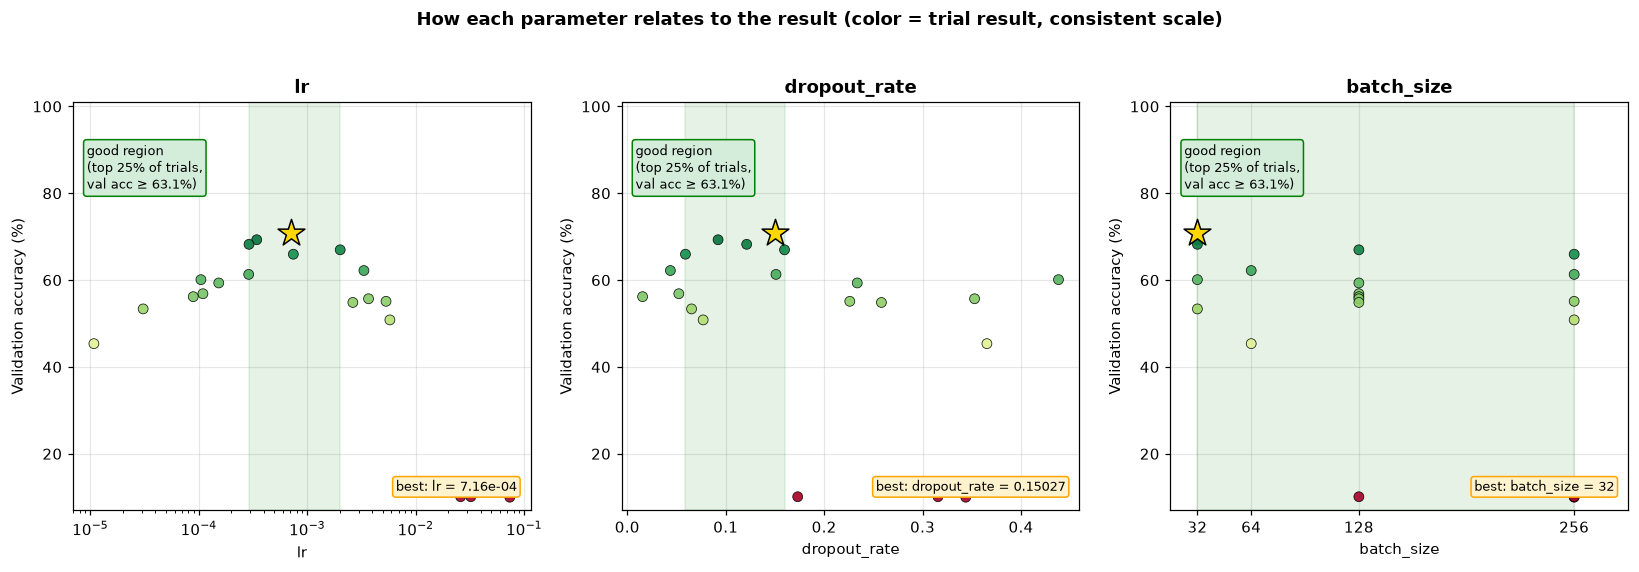

In [25]:
# ---------------- (3) per-parameter "slice" scatters ----------------
params = study.best_trial.params            # best trial's settings, for the star markers
good_thr = float(np.percentile(values, 75)) # "good" = top quartile of all trials

fig, (ax_lr, ax_dro, ax_bs) = plt.subplots(1, 3, figsize=(15, 5))
spec = [
    (ax_lr,  "lr",           [t.params["lr"] for t in trials]),
    (ax_dro, "dropout_rate", [t.params["dropout_rate"] for t in trials]),
    (ax_bs,  "batch_size",   [t.params["batch_size"] for t in trials]),
]
for ax, name, xs in spec:
    if name == "lr":
        ax.set_xscale("log")
    ax.scatter(xs, values, c=values, cmap=cmap, vmin=norm.vmin, vmax=norm.vmax,
               s=42, edgecolor="black", linewidth=0.5, zorder=3, alpha=0.9)
    good = [x for x, y in zip(xs, values) if y >= good_thr]
    lo, hi = min(good), max(good)
    ax.axvspan(lo, hi, color="green", alpha=0.10)
    ax.text(0.03, 0.90, f"good region\n(top 25% of trials,\nval acc \u2265 {good_thr:.1f}%)",
            transform=ax.transAxes, va="top", zorder=10,
            fontsize=8.5, bbox=dict(boxstyle="round,pad=0.25", fc="#d4edda", ec="green"))
    bxs = params[name]
    star_lbl = f"best: {name} = {bxs:.2e}" if name == "lr" else f"best: {name} = {bxs:g}"
    ax.scatter(bxs, values.max(), s=340, marker="*", facecolor="gold",
               edgecolor="black", linewidth=1.0, zorder=5)
    ax.text(0.97, 0.04, star_lbl, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=8.5, zorder=10, bbox=dict(boxstyle="round,pad=0.25", fc="#fff3cd", ec="orange"))
    if name == "batch_size":
        ax.set_xticks([32, 64, 128, 256], ["32", "64", "128", "256"])
        ax.set_xlim(16, 288)
    ax.set_title(name)
    ax.set_xlabel(name); ax.set_ylabel("Validation accuracy (%)")
    ax.set_ylim(min(values) - 3, 101)
plt.suptitle("How each parameter relates to the result (color = trial result, consistent scale)",
             y=1.03, fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()


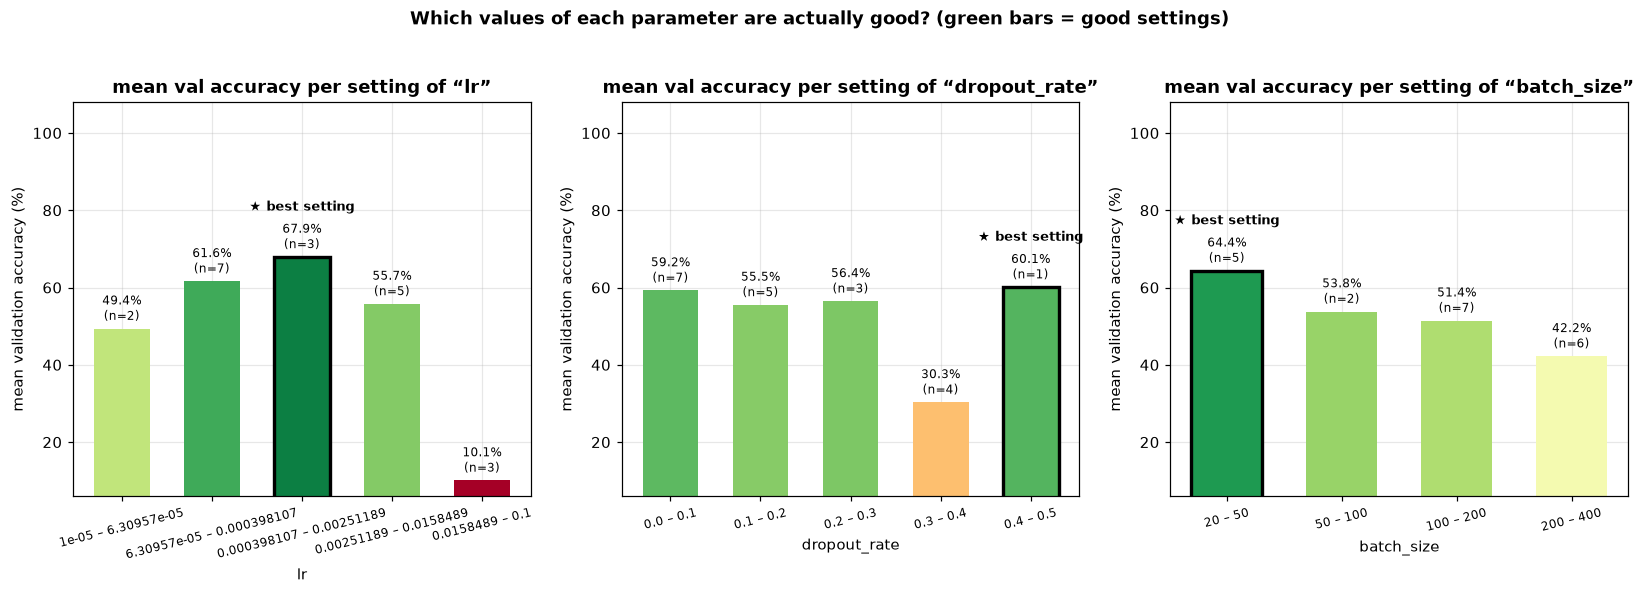

In [26]:
# ---------------- (4) mean effect of each parameter, grouped by setting -----
def grouped(name, edges):
    """Mean/std/count of trial results per bin of a parameter."""
    xs = [t.params[name] for t in trials]
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = [x >= lo and (x < hi or hi == edges[-1]) for x in xs]
        ys = [v for v, f in zip(values, m) if f]
        if ys:
            label = (f"{lo:g} \u2013 {hi:g}") if name != "dropout_rate" \
                    else f"{lo:.1f} \u2013 {hi:.1f}"
            rows.append((label, float(np.mean(ys)), int(len(ys))))
    return rows

fig, (ax_lr, ax_dro, ax_bs) = plt.subplots(1, 3, figsize=(15, 5.2))

def draw(ax, name, edges):
    rows = grouped(name, edges)
    xpos = np.arange(len(rows))
    means = [r[1] for r in rows]
    bars = ax.bar(xpos, means, width=0.62,
                  color=[plt.get_cmap("RdYlGn")(norm(m)) for m in means])
    for b, (label, mu, n) in zip(bars, rows):
        ax.text(b.get_x() + b.get_width() / 2, mu + 1.2,
                f"{mu:.1f}%\n(n={n})", ha="center", va="bottom", fontsize=8)
    best_i = int(np.argmax(means))
    bars[best_i].set_edgecolor("black"); bars[best_i].set_linewidth(2.2)
    ax.text(xpos[best_i], means[best_i] + 12, "\u2605 best setting",
            ha="center", fontsize=8.5, fontweight="bold")
    ax.set_title(f"mean val accuracy per setting of \u201c{name}\u201d")
    ax.set_xlabel(name); ax.set_ylabel("mean validation accuracy (%)")
    ax.set_xticks(xpos, [r[0] for r in rows], fontsize=8, rotation=14)
    ax.set_ylim(min(values) - 4, 108)

draw(ax_lr,  "lr",           np.logspace(-5, -1, 6))
draw(ax_dro, "dropout_rate", np.linspace(0.0, 0.5, 6))
draw(ax_bs,  "batch_size",   [20, 50, 100, 200, 400])   # one bin per category
plt.suptitle("Which values of each parameter are actually good? (green bars = good settings)",
             y=1.03, fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()


### Reading the Optuna results

- **Chart 1 (history):** do later dots get greener than early ones? Then the search is converging — Optuna is learning *where* the good settings live.
- **Chart 2 (slices):** each panel answers "which values of *one* parameter do good trials use?" — the shaded green band is covered by the top quartile of trials, and the ⭐ star shows the exact setting of the best trial.
- **Chart 3 (grouped means):** averages out the noise of individual trials. Settings with small *n* (few trials) are less trustworthy — give them more trials before acting on them. The black-outlined bar is the best-averaged setting per parameter.
- **Practical next step:** retake the best trial's hyperparameters, retrain at full 10+ epochs (each trial above was cut at 3 for speed), and check the result on the untouched test set.
